# Black-box top-k rankings (V2)

"Which patterns keep recurring?"

Ranking modes:

1. `damaging_sources_for_targets` -- top-k most damaging sources per target (main).
2. `robust_targets_for_sources` -- top-k most robust targets per source (main).
3. `least_damaging_sources_for_targets` -- exploratory.
4. `least_robust_targets_for_sources` -- exploratory.

Figure variants (for both recurring damaging sources and recurring robust targets):

- **A `rank1_vs_topk`**: bar = top-k count, darker segment = rank-1 count.
- **B `rank_decomposition`**: stacked rank-1 / rank-2 / rank-3 counts.
- **C `family_composition`**: stacked by the family of the opposite side.
- **D `family_split_rank1_vs_topk`**: per-family bars, dark rank-1 + light rest.

# Black-box transfer analytics V2 -- shared configuration

All four `attacksv2_*` notebooks use the same `AttacksV2Config` object and the same
filtering/blacklist/aggregation backend (`analytics.attacks.attacksv2_transfer_tools`),
so the scatter, matrix, top-k rankings, and asymmetry tables are directly comparable.

Key knobs:

- `metric`: `"Transfer ASR"` (default), `"Transfer Robust Accuracy"`, `"Accuracy Drop"`,
  `"Mean Confidence Drop"`, `"Mean Margin Drop"`, ... Ranking direction is handled
  automatically (e.g. for robust-target rankings, lower ASR but *higher* robust accuracy
  is more robust).
- `source_grain` / `target_grain`: `"family"`, `"architecture"`, or `"variant"`.
- `comparison_mode`:
  - `"inter_variant"`: exclude exact same variant/model only.
  - `"inter_architecture"`: exclude same-architecture pairs.
  - `"inter_family"`: exclude same-family pairs.
- `variant_aggregate_mode`: `"none"` (variant grain only), `"mean"`, `"median"`,
  `"best_damage"`, `"best_robust"`, `"manual_representative"` (with
  `manual_representatives=((arch_substring, variant_substring), ...)`).
- `architecture_aggregate_mode`: `"mean"`, `"median"`, `"best_damage"`, `"best_robust"`.
- `split_quantum_ansatz_as_architecture`: turn ansatz variants into pseudo-architectures
  (`VQM-Basic`, `VQM-Strong`, `HVQL-Random`, ...) consistently across all views.
- `blacklist_exact` / `blacklist_contains` (e.g. `("HQuanv",)`).
- `selected_rows` / `selected_columns`: explicit group selection + ordering.
- `top_k` (default 3) and `output_dir` (default `outputs/attacksv2_transfer/`).

Templates: `architecture_main`, `architecture_with_variants`, `variant_spread`,
`family_synthesis`, `ansatz_split`, `topk_main_architecture` -- see `list_v2_templates()`.


In [1]:
from pathlib import Path
import sys

try:
    from analytics.paths import find_project_root, output_dir
except ModuleNotFoundError:
    # Allow running the notebook from anywhere inside the repo.
    repo_root = Path.cwd()
    while repo_root != repo_root.parent and not (repo_root / "src").exists():
        repo_root = repo_root.parent
    sys.path.insert(0, str(repo_root / "src"))
    from analytics.paths import find_project_root, output_dir

from analytics.attacks.attacksv2_transfer_tools import (
    AttacksV2Config,
    V2_TEMPLATES,
    get_v2_template,
    list_v2_templates,
    v2_output_dir,
    metric_direction_notes,
    load_or_build_pair_metrics,
    export_table,
    export_figure,
    build_source_target_scatter,
    plot_source_target_scatter,
    build_attack_matrix,
    plot_attack_matrix,
    build_topk_instances,
    summarize_recurring,
    build_recurring_damaging_sources,
    build_recurring_robust_targets,
    plot_topk_ranking,
    build_directional_pair_table,
    plot_directional_asymmetry_bars,
    run_smoke_test,
)

ROOT = find_project_root()
PAIR_METRICS_CACHE = output_dir(ROOT, "attack_transfer_role_tables") / "pair_metrics.csv"


In [2]:
# Template selection -- run list_v2_templates() to inspect all presets.
TEMPLATE_NAME = "topk_main_architecture"
CONFIG = get_v2_template(TEMPLATE_NAME)
list_v2_templates()


,template,source_grain,target_grain,comparison_mode,metric,top_k,variant_aggregate_mode,architecture_aggregate_mode,split_ansatz_as_architecture,include_no_entangling_as_ansatz,...,target_architecture_filter,source_contains,target_contains,blacklist_exact,split_quantum_ansatz_as_architecture,selected_rows,selected_columns,scatter_display_mode,manual_representatives,output_dir
0,architecture_main,architecture,architecture,inter_architecture,Transfer ASR,3,mean,mean,False,True,...,None,None,None,(),False,None,None,architectures_only,(),None
1,architecture_with_variants,architecture,architecture,inter_architecture,Transfer ASR,3,mean,mean,False,True,...,None,None,None,(),False,None,None,both,(),None
2,variant_spread,variant,variant,inter_architecture,Transfer ASR,3,mean,mean,False,True,...,None,None,None,(),False,None,None,variants_only,(),None
3,family_synthesis,family,family,inter_family,Transfer ASR,3,mean,mean,False,True,...,None,None,None,(),False,None,None,architectures_only,(),None
4,ansatz_split,architecture,architecture,inter_architecture,Transfer ASR,3,mean,mean,True,True,...,None,None,None,(),True,None,None,architectures_only,(),None
5,topk_main_architecture,architecture,architecture,inter_architecture,Transfer ASR,3,mean,mean,False,True,...,None,None,None,(),False,None,None,architectures_only,(),None


In [3]:
# Optional overrides -- uncomment and edit, then re-run the cells below.
CONFIG = CONFIG.with_updates(
    # metric="Transfer Robust Accuracy",
    # source_grain="variant",
    # target_grain="variant",
    # comparison_mode="inter_family",
    # variant_aggregate_mode="best_damage",
    # architecture_aggregate_mode="mean",
    # split_quantum_ansatz_as_architecture=True,
    # blacklist_exact=("Quantum/VQM/some_variant",),
    # blacklist_contains=("HQuanv",),
    # selected_rows=("Quantum/VQM", "Classical/CNN"),
    # selected_columns=None,
    # top_k=3,
    # output_dir=None,  # defaults to outputs/attacksv2_transfer/
)
CONFIG

# Figure controls.
SORT_BY = "topk_count"      # "topk_count", "rank1_count", or a custom entity list
MAX_ROWS = None             # e.g. 10
SELECTED_ENTITIES = None    # e.g. ("Quantum/VQM", "Classical/CNN")
FIGURE_VARIANTS = ("rank1_vs_topk", "rank_decomposition",
                   "family_composition", "family_split_rank1_vs_topk")

In [4]:
pair_df = load_or_build_pair_metrics(pair_metrics_cache=PAIR_METRICS_CACHE, rebuild=False)
print(f"Loaded pair metrics: {pair_df.shape[0]:,} rows x {pair_df.shape[1]:,} columns")
metric_direction_notes(CONFIG.metric)


Loaded pair metrics: 1,089 rows x 24 columns


{'source': 'higher Transfer ASR = more damaging source',
 'target': 'higher Transfer ASR = more vulnerable target',
 'robust_target': 'lower Transfer ASR = more robust target'}

In [5]:
OUT_DIR = v2_output_dir("topk", CONFIG)
RANKING_MODES = (
    "damaging_sources_for_targets",
    "robust_targets_for_sources",
    "least_damaging_sources_for_targets",   # exploratory
    "least_robust_targets_for_sources",     # exploratory
)
long_tables = {}
for mode in RANKING_MODES:
    long_tables[mode] = build_topk_instances(pair_df, CONFIG, ranking_mode=mode)
    export_table(long_tables[mode], OUT_DIR, f"topk_long__{mode}__{CONFIG.slug()}")
    print(mode, long_tables[mode].shape)
long_tables["damaging_sources_for_targets"].head(12)

damaging_sources_for_targets (30, 13)
robust_targets_for_sources (30, 13)
least_damaging_sources_for_targets (30, 13)
least_robust_targets_for_sources (30, 13)


,query_group,candidate_group,query_family,candidate_family,query_architecture,candidate_architecture,rank,metric_value,metric_name,ranking_mode,comparison_mode,source_grain,target_grain
0,Classical/CNN,Hybrid/HQuanv,Classical,Hybrid,Classical/CNN,Hybrid/HQuanv,1,0.807103,Transfer ASR,damaging_sources_for_targets,inter_architecture,architecture,architecture
1,Classical/CNN,Classical/MLP,Classical,Classical,Classical/CNN,Classical/MLP,2,0.780563,Transfer ASR,damaging_sources_for_targets,inter_architecture,architecture,architecture
2,Classical/CNN,Classical/ResNet18,Classical,Classical,Classical/CNN,Classical/ResNet18,3,0.677878,Transfer ASR,damaging_sources_for_targets,inter_architecture,architecture,architecture
3,Classical/MLP,Hybrid/HQuanv,Classical,Hybrid,Classical/MLP,Hybrid/HQuanv,1,0.863841,Transfer ASR,damaging_sources_for_targets,inter_architecture,architecture,architecture
4,Classical/MLP,Classical/CNN,Classical,Classical,Classical/MLP,Classical/CNN,2,0.837322,Transfer ASR,damaging_sources_for_targets,inter_architecture,architecture,architecture
5,Classical/MLP,Classical/ResNet18,Classical,Classical,Classical/MLP,Classical/ResNet18,3,0.750405,Transfer ASR,damaging_sources_for_targets,inter_architecture,architecture,architecture
6,Classical/MLPMixer,Classical/CNN,Classical,Classical,Classical/MLPMixer,Classical/CNN,1,0.792040,Transfer ASR,damaging_sources_for_targets,inter_architecture,architecture,architecture
7,Classical/MLPMixer,Hybrid/HQuanv,Classical,Hybrid,Classical/MLPMixer,Hybrid/HQuanv,2,0.771493,Transfer ASR,damaging_sources_for_targets,inter_architecture,architecture,architecture
8,Classical/MLPMixer,Classical/MLP,Classical,Classical,Classical/MLPMixer,Classical/MLP,3,0.756354,Transfer ASR,damaging_sources_for_targets,inter_architecture,architecture,architecture
9,Classical/ResNet18,Hybrid/HPVQL,Classical,Hybrid,Classical/ResNet18,Hybrid/HPVQL,1,0.762648,Transfer ASR,damaging_sources_for_targets,inter_architecture,architecture,architecture


In [6]:
damaging_summary = summarize_recurring(
    long_tables["damaging_sources_for_targets"], CONFIG)
robust_summary = summarize_recurring(
    long_tables["robust_targets_for_sources"], CONFIG)
export_table(damaging_summary, OUT_DIR, f"recurring_damaging_sources__{CONFIG.slug()}", latex=True)
export_table(robust_summary, OUT_DIR, f"recurring_robust_targets__{CONFIG.slug()}", latex=True)
damaging_summary

,entity,family,architecture,rank1_count,rank2_count,rank3_count,topk_count,topk_family_classical_count,rank1_family_classical_count,topk_family_hybrid_count,rank1_family_hybrid_count,topk_family_quantum_count,rank1_family_quantum_count
0,Hybrid/HQuanv,Hybrid,Hybrid/HQuanv,4,3,1,8,3,2,4,2,1,0
1,Classical/CNN,Classical,Classical/CNN,2,5,1,8,2,1,5,1,1,0
2,Classical/MLP,Classical,Classical/MLP,2,1,3,6,2,0,3,1,1,1
3,Classical/ResNet18,Classical,Classical/ResNet18,0,0,3,3,2,0,1,0,0,0
4,Hybrid/HPVQL,Hybrid,Hybrid/HPVQL,2,0,0,2,1,1,1,1,0,0
5,Classical/MLPMixer,Classical,Classical/MLPMixer,0,0,1,1,1,0,0,0,0,0
6,Hybrid/HVQL,Hybrid,Hybrid/HVQL,0,1,0,1,1,0,0,0,0,0
7,Quantum/VQM,Quantum,Quantum/VQM,0,0,1,1,0,0,1,0,0,0


In [7]:
robust_summary

,entity,family,architecture,rank1_count,rank2_count,rank3_count,topk_count,topk_family_classical_count,rank1_family_classical_count,topk_family_hybrid_count,rank1_family_hybrid_count,topk_family_quantum_count,rank1_family_quantum_count
0,Quantum/VQM,Quantum,Quantum/VQM,9,0,0,9,4,4,5,5,0,0
1,Hybrid/HQuanv,Hybrid,Hybrid/HQuanv,0,5,1,6,2,0,3,0,1,0
2,Hybrid/HVQM,Hybrid,Hybrid/HVQM,0,3,3,6,3,0,3,0,0,0
3,Hybrid/HPVQL,Hybrid,Hybrid/HPVQL,0,2,3,5,2,0,2,0,1,0
4,Hybrid/HVQL,Hybrid,Hybrid/HVQL,0,0,2,2,1,0,1,0,0,0
5,Classical/CNN,Classical,Classical/CNN,1,0,0,1,0,0,0,0,1,1
6,Hybrid/HQE,Hybrid,Hybrid/HQE,0,0,1,1,0,0,1,0,0,0


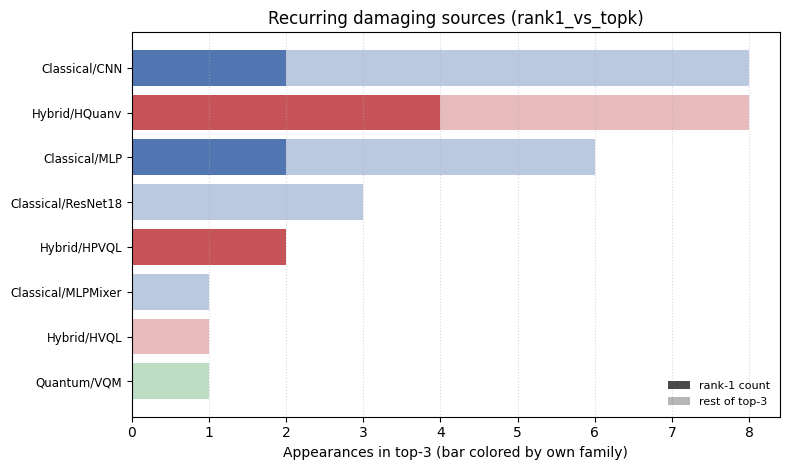

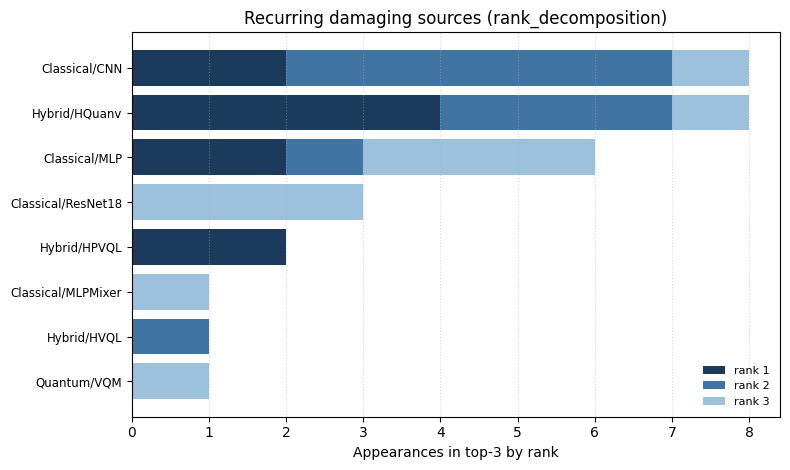

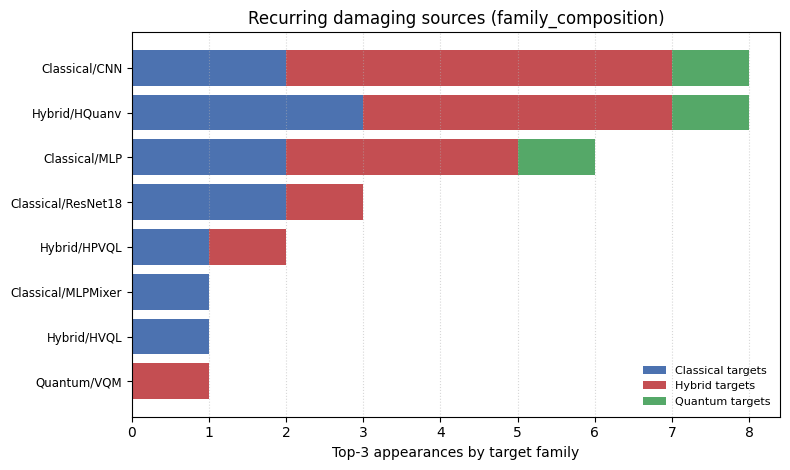

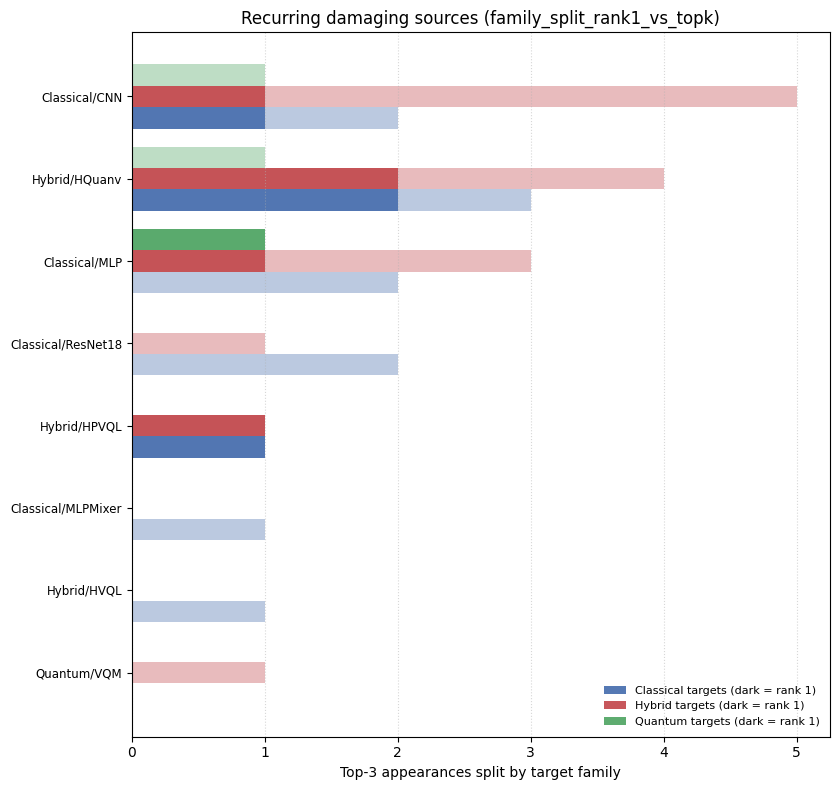

In [8]:
# Recurring damaging sources -- all figure variants.
for variant in FIGURE_VARIANTS:
    fig, ax = plot_topk_ranking(
        damaging_summary, CONFIG, variant=variant, role="source",
        selected_entities=SELECTED_ENTITIES, sort_by=SORT_BY, max_rows=MAX_ROWS,
    )
    export_figure(fig, OUT_DIR, f"recurring_damaging_sources__{variant}__{CONFIG.slug()}")

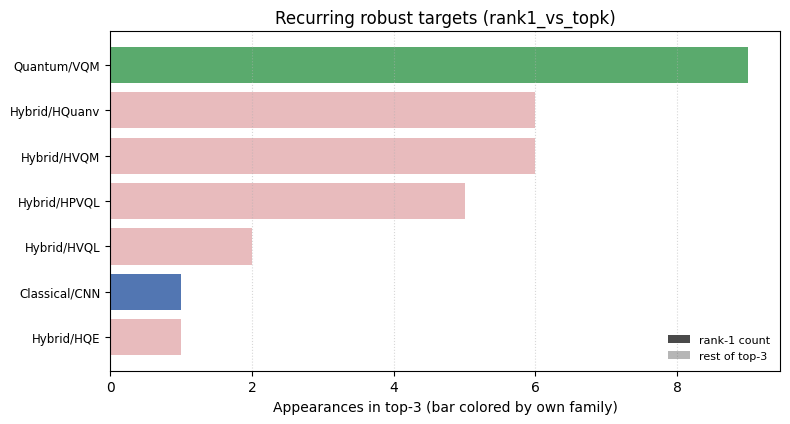

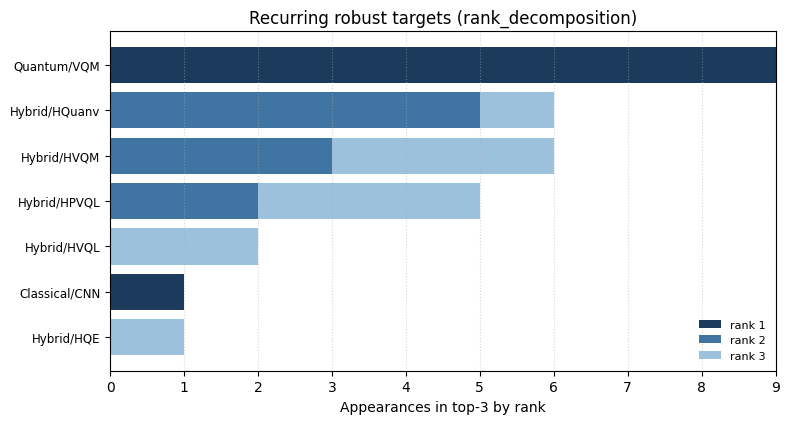

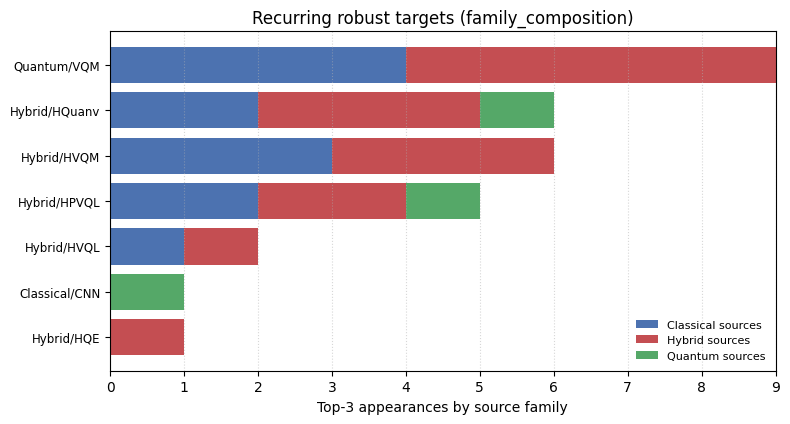

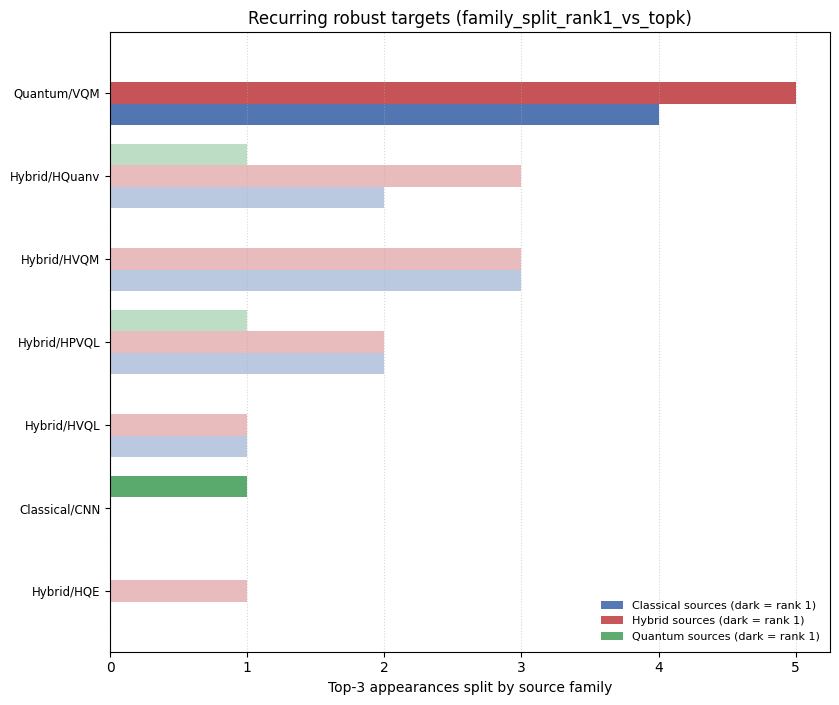

In [9]:
# Recurring robust targets -- all figure variants.
for variant in FIGURE_VARIANTS:
    fig, ax = plot_topk_ranking(
        robust_summary, CONFIG, variant=variant, role="target",
        selected_entities=SELECTED_ENTITIES, sort_by=SORT_BY, max_rows=MAX_ROWS,
    )
    export_figure(fig, OUT_DIR, f"recurring_robust_targets__{variant}__{CONFIG.slug()}")

In [10]:
# Synthetic-data smoke test: verifies scatter, matrix, top-k summaries, and
# the directional asymmetry table all build with the shared backend.
_ = run_smoke_test(verbose=True)


[smoke] scatter: 14 rows x 13 cols
[smoke] matrix: 5 rows x 5 cols
[smoke] topk_long_damaging_sources_for_targets: 15 rows x 13 cols
[smoke] topk_long_robust_targets_for_sources: 15 rows x 13 cols
[smoke] topk_long_least_damaging_sources_for_targets: 15 rows x 13 cols
[smoke] topk_long_least_robust_targets_for_sources: 15 rows x 13 cols
[smoke] recurring_damaging_sources: 5 rows x 13 cols
[smoke] recurring_robust_targets: 5 rows x 13 cols
[smoke] asymmetry: 10 rows x 14 cols
[smoke] matrix_ansatz: 9 rows x 9 cols
[smoke] scatter_family: 3 rows x 13 cols
[smoke] all checks passed
